# **Downloading the Refined IDRID segmentation dataset**

For our Diabetic retinopathy segmentation images, we decided to go with [Refined IDRiD](https://www.mdpi.com/2306-5729/11/2/30) as it identified and corrected some issues within the widely adopted Indian Diabetic Retinopathy Image Dataset

In [1]:
import os
import cv2
import numpy as np
import glob
from PIL import Image
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
name = "aveera"

In [ ]:
IDRID_DIR = f"/data/{name}/Refined IDRiD"

IDRID_SPLIT_DIRS = [
    os.path.join(IDRID_DIR, "Test", "Test"),
    os.path.join(IDRID_DIR, "Train", "Train"),
]

PREPROCESSED_DIR = f"/data/{name}/preprocessed_idrid"

for split_dir in IDRID_SPLIT_DIRS:
    assert os.path.isdir(os.path.join(split_dir, "Images")), (
        f"Expected an 'Images' folder inside {split_dir} -- check IDRID_DIR."
    )
print(f"Using Refined IDRiD data from '{IDRID_DIR}' (Test + Train splits)")

for split_dir in IDRID_SPLIT_DIRS:
    assert os.path.isdir(os.path.join(split_dir, "Images")), (f"Expected an 'Images' folder inside {split_dir} -- check IDRID_DIR / your Drive layout.")

print(f"Using Refined IDRiD data from '{IDRID_DIR}' (Test + Train splits)")


Using Refined IDRiD data from '/data/aveera/Refined IDRiD' (Test + Train splits)
Using Refined IDRiD data from '/data/aveera/Refined IDRiD' (Test + Train splits)


**The segmentation dataset we are using has some features that aren't useful to us like the background or anatomical structure, so we remove them from our masks.**

In [4]:
# Grabbing the pixel values of all the lesions
LESION_LABEL_IDS = {
    4,    # Vitreous Hemorrhage (VH)
    63,   # Hard Exudate (EX)
    96,   # IRMA
    127,  # Hemorrhage (HE)
    166,  # Neovascularization (NV)
    191,  # Cotton-Wool Spot (CWS)
    255,  # Microaneurysm (MA)
}

**Downsample a binary mask so that any block containing at least**
**one lesion pixel is marked as lesion in the output.**

Microaneurysms can be as small as a few pixels, so after this shrinking they become smaller than a single pixel in our masks. If we only marked a pixel as "lesion" when most of its area was lesion, nearly all microaneurysms would simply vanish from the ground truth. Instead, we mark a pixel as "lesion" if any part of it touched a lesion at all. This makes lesion boundaries look slightly larger than they truly are, but ensures we don't lose the smallest and most important lesions entirely.

In [ ]:
def resize_mask_no_loss(mask, target_size):
    mask_f = mask.astype(np.float32)
    coverage = cv2.resize(mask_f, target_size, interpolation=cv2.INTER_AREA)
    # any nonzero coverage in the box -> lesion touched that region
    return (coverage > 0).astype(np.uint8)

def load_and_preprocess(split_dirs, target_size=(224, 224), max_images=None, sigmaX=30, save_dir=None):
    if save_dir is not None:
        images_out_dir = os.path.join(save_dir, "images")
        masks_out_dir = os.path.join(save_dir, "masks")
        os.makedirs(images_out_dir, exist_ok=True)
        os.makedirs(masks_out_dir, exist_ok=True)

    samples = []
    for split_dir in split_dirs:
        images_dir = os.path.join(split_dir, "Images")
        labels_dir = os.path.join(split_dir, "Labels")

        image_paths = sorted(glob.glob(os.path.join(images_dir, "*.jpg")))
        for img_path in image_paths:
            if split_dir == os.path.normpath("/data/aveera/Refined IDRiD/Train/Train"): 
              image_id = os.path.splitext(os.path.basename(img_path))[0]+"_vessel"
            else:
              image_id = os.path.splitext(os.path.basename(img_path))[0] 

            mask_path = os.path.join(labels_dir, f"{image_id}.png")
            if not os.path.isfile(mask_path):
                continue

            if save_dir is not None:
                img_out_path = os.path.join(images_out_dir, f"{image_id}.png")
                mask_out_path = os.path.join(masks_out_dir, f"{image_id}.png")
                if os.path.isfile(img_out_path) and os.path.isfile(mask_out_path):
                    img_resized = np.array(Image.open(img_out_path).convert('RGB'))
                    mask_resized = np.array(Image.open(mask_out_path).convert('L'))
                    samples.append((img_resized, mask_resized))
                    if max_images is not None and len(samples) >= max_images:
                        return samples
                    continue

            raw_mask = np.array(Image.open(mask_path).convert('L'))
            raw_img = np.array(Image.open(img_path).convert('RGB'))

            # Resizes the lesion mask if the height and width aren't the same as the original image
            if raw_mask.shape[:2] != raw_img.shape[:2]:
                raw_mask = cv2.resize(raw_mask, (raw_img.shape[1], raw_img.shape[0]),interpolation=cv2.INTER_NEAREST)


            green_channel = raw_img[:, :, 1] 

            clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
            enhanced_green = clahe.apply(green_channel) 

            bgr_enhanced = cv2.merge([enhanced_green, enhanced_green, enhanced_green]) # Merge into a clean 3-channel layout 
            
            rgb_enhanced = cv2.cvtColor(bgr_enhanced, cv2.COLOR_BGR2RGB)

            img_resized = cv2.resize(rgb_enhanced, (224, 224), interpolation=cv2.INTER_CUBIC)# Resize the image

            # Keep only lesion pixels and exclude background and the 4 anatomical classes
            lesion_mask = np.isin(raw_mask, list(LESION_LABEL_IDS)).astype(np.uint8)

            mask_resized = resize_mask_no_loss(lesion_mask, target_size)

            samples.append((img_resized, mask_resized))

            # Save so the next notebook (or next run) can just load these
            if save_dir is not None:
                Image.fromarray(img_resized).save(img_out_path)
                Image.fromarray(mask_resized).save(mask_out_path)

            if max_images is not None and len(samples) >= max_images:
                return samples
        print("There are ", len(samples)," images in ", split_dir)

    return samples

**Loading the preprocessed Refined IDRiD dataset**

In [7]:
idrid_subset = load_and_preprocess(IDRID_SPLIT_DIRS, sigmaX=30, save_dir=PREPROCESSED_DIR)

print(f"IDRiD localization-evaluation subset (circle-crop preprocessed, same pipeline as APTOS): "
      f"{len(idrid_subset)} images with lesion masks")


There are  27  images in  /data/aveera/Refined IDRiD/Test/Test


There are  81  images in  /data/aveera/Refined IDRiD/Train/Train
IDRiD localization-evaluation subset (circle-crop preprocessed, same pipeline as APTOS): 81 images with lesion masks


**Function to load preprocessed images**

In [8]:
def load_preprocessed_from_disk(save_dir):
    images_out_dir = os.path.join(save_dir, "images")
    masks_out_dir = os.path.join(save_dir, "masks")

    image_paths = sorted(glob.glob(os.path.join(images_out_dir, "*.png")))
    if not image_paths:
        raise FileNotFoundError(f"No preprocessed images found in {images_out_dir}")

    samples = []
    for img_path in image_paths:
        image_id = os.path.splitext(os.path.basename(img_path))[0]
        mask_path = os.path.join(masks_out_dir, f"{image_id}.png")

        img = np.array(Image.open(img_path).convert('RGB'))
        mask = np.array(Image.open(mask_path).convert('L'))
        samples.append((img, mask))
    return samples

**Side-by-side comparison of before and after image preprocessing**

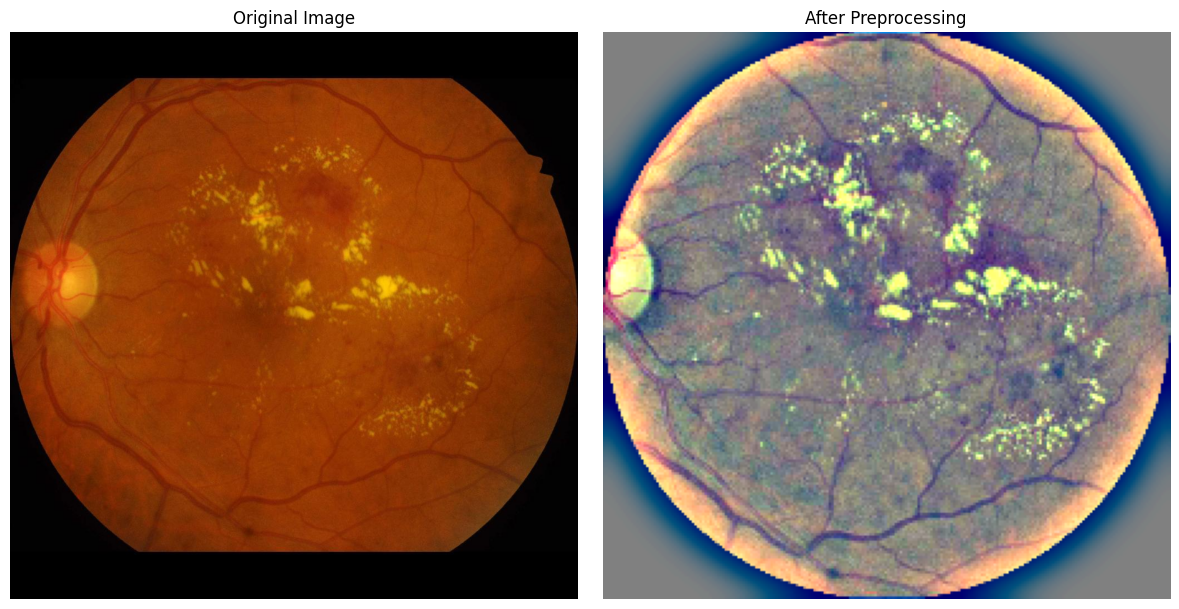

In [ ]:
def show_idrid_before_after(split_dirs, index=0, target_size=(224, 224)):
    all_image_paths = []
    for split_dir in split_dirs:
        images_dir = os.path.join(split_dir, "Images")
        all_image_paths.extend(sorted(glob.glob(os.path.join(images_dir, "*.jpg"))))

    if not all_image_paths:
        raise FileNotFoundError("No .jpg images found in the given split directories.")

    img_path = all_image_paths[index]
    raw_img = np.array(Image.open(img_path).convert('RGB'))

    # Same steps as load_and_preprocess
    green_channel = raw_img[:, :, 1]
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced_green = clahe.apply(green_channel)
    bgr_enhanced = cv2.merge([enhanced_green, enhanced_green, enhanced_green]) # Merge into a clean 3-channel layout 
    rgb_enhanced = cv2.cvtColor(bgr_enhanced, cv2.COLOR_BGR2RGB)
    processed_img = cv2.resize(rgb_enhanced, (224, 224), interpolation=cv2.INTER_CUBIC)

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    axes[0].imshow(raw_img)
    axes[0].set_title("Original Image")
    axes[0].axis("off")
    axes[1].imshow(processed_img)
    axes[1].set_title("After Preprocessing")
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()

show_idrid_before_after([IDRID_SPLIT_DIRS[0]])

**Side-by-side comparison of of the mask before and after we remove the anatomical structures.**

Sample: IDRiD_55f055
Unique label values in raw mask: [0, 8, 16, 24, 32, 63, 127, 191, 255]
Lesion pixels after filtering: 5.23% of image
Lesion pixel count: 2623


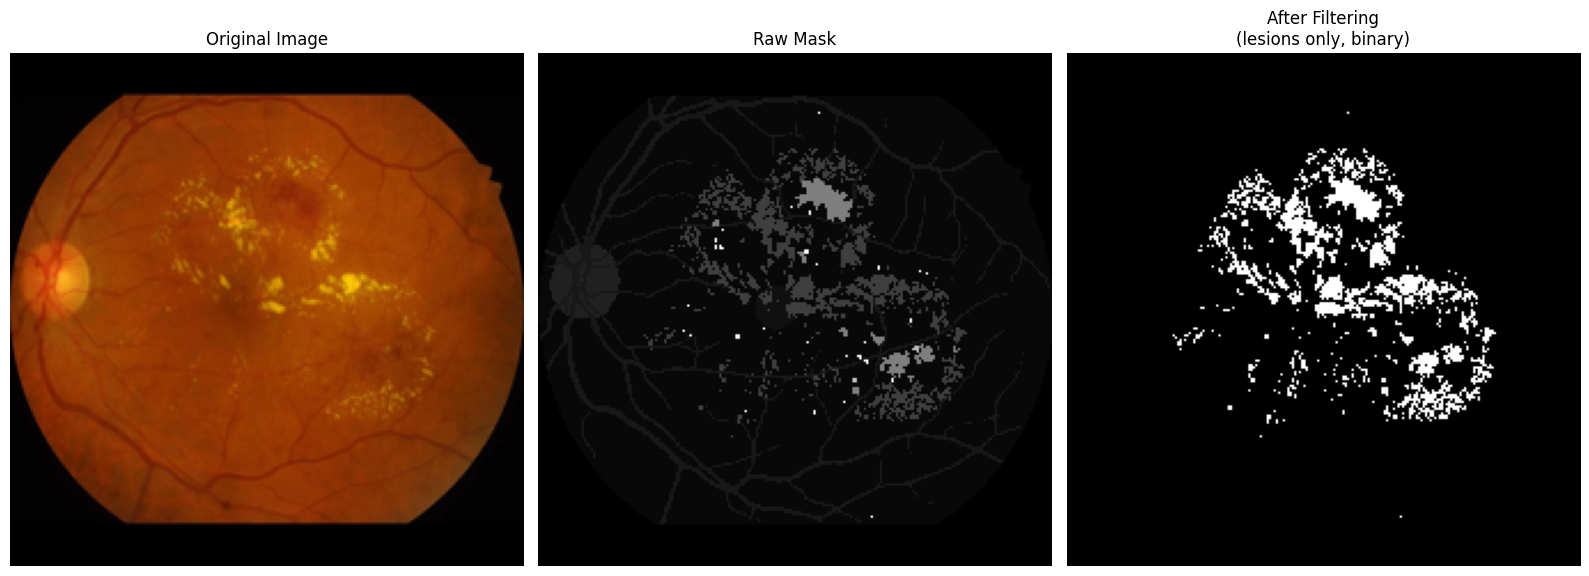

In [10]:
split_dir = IDRID_SPLIT_DIRS[0]
images_dir = os.path.join(split_dir, "Images")
labels_dir = os.path.join(split_dir, "Labels")

sample_img_path = sorted(glob.glob(os.path.join(images_dir, "*.jpg")))[0]

if os.path.normpath(split_dir) == os.path.normpath("/data/aveera/Refined IDRiD/Train/Train"):
    image_id = os.path.splitext(os.path.basename(sample_img_path))[0] + "_vessel"
else:
    image_id = os.path.splitext(os.path.basename(sample_img_path))[0]

sample_mask_path = os.path.join(labels_dir, f"{image_id}.png")
target_size = (224, 224)

raw_img = np.array(Image.open(sample_img_path).convert('RGB').resize(target_size))
raw_mask_native = np.array(Image.open(sample_mask_path).convert('L'))

raw_mask = cv2.resize(raw_mask_native, target_size, interpolation=cv2.INTER_NEAREST)

lesion_only_mask = np.isin(raw_mask, list(LESION_LABEL_IDS)).astype(np.uint8)

print(f"Sample: {image_id}")
print(f"Unique label values in raw mask: {sorted(np.unique(raw_mask).tolist())}")
print(f"Lesion pixels after filtering: {lesion_only_mask.mean():.2%} of image")
print(f"Lesion pixel count: {lesion_only_mask.sum()}")

fig, axes = plt.subplots(1, 3, figsize=(16, 6))

axes[0].imshow(raw_img)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(raw_mask, cmap="gray")
axes[1].set_title("Raw Mask")
axes[1].axis("off")

axes[2].imshow(lesion_only_mask, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("After Filtering\n(lesions only, binary)")
axes[2].axis("off")

plt.tight_layout()
plt.show()